# Step 2 - Logistic regression baseline (Ilgaz)

K-mer counts and TF-IDF (k = 3..6), logistic regression, C tuned on **dev only**. Test is scored once, at the end, for the dev-chosen model.

In [1]:
import re, time
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("..") / "data" / "prom_300_all"   # Code/data/prom_300_all
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
PROM, NON = "#2a78d6", "#eb6834"                   # blue = promoter (1), orange = not promoter (0)
train, dev, test = [pd.read_csv(DATA_DIR / f"{s}.csv") for s in ("train", "dev", "test")]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ecebe8", "figure.dpi": 110})
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import matthews_corrcoef, accuracy_score, f1_score, roc_auc_score, confusion_matrix

In [2]:
def scores(y, p):
    yh = (p >= 0.5).astype(int)
    return dict(mcc=matthews_corrcoef(y, yh), acc=accuracy_score(y, yh), f1=f1_score(y, yh), auc=roc_auc_score(y, p))

grid = []
for k in (3, 4, 5, 6):
    for kind, V in (("counts", CountVectorizer), ("tfidf", TfidfVectorizer)):
        vec = V(analyzer="char", ngram_range=(k, k), lowercase=False)
        Xtr, Xdev = vec.fit_transform(train.sequence), vec.transform(dev.sequence)
        for C in (0.01, 0.1, 1.0):
            t0 = time.time()
            clf = LogisticRegression(C=C, max_iter=2000).fit(Xtr, train.label)
            s = scores(dev.label, clf.predict_proba(Xdev)[:, 1])
            grid.append(dict(k=k, features=kind, C=C, seconds=round(time.time() - t0, 1), **{m: round(v, 4) for m, v in s.items()}))
grid = pd.DataFrame(grid); grid.to_csv(RESULTS_DIR / "logreg_dev_grid.csv", index=False)
best = grid.loc[grid.groupby(["k", "features"]).mcc.idxmax()].reset_index(drop=True)
best

,k,features,C,seconds,mcc,acc,f1,auc
0,3,counts,0.10,0.4,0.7304,0.8652,0.8647,0.9306
1,3,tfidf,0.10,0.1,0.7568,0.8784,0.8769,0.9422
2,4,counts,0.01,0.8,0.7483,0.8742,0.8738,0.9398
3,4,tfidf,1.00,0.2,0.7700,0.8850,0.8849,0.9476
4,5,counts,0.01,2.2,0.7696,0.8848,0.8849,0.9475
5,5,tfidf,1.00,0.4,0.7795,0.8897,0.8898,0.9513
6,6,counts,0.01,1.7,0.7786,0.8892,0.8898,0.9531
7,6,tfidf,1.00,0.8,0.7845,0.8922,0.8925,0.9548


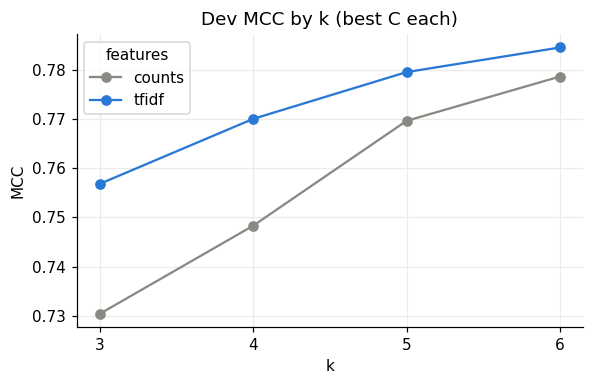

In [3]:
piv = best.pivot(index="k", columns="features", values="mcc")
ax = piv.plot(marker="o", figsize=(5.5, 3.6), color=["#8a8984", PROM])
ax.set(title="Dev MCC by k (best C each)", ylabel="MCC", xticks=[3, 4, 5, 6]); plt.tight_layout()
plt.savefig(RESULTS_DIR / "logreg_mcc_by_k.png", dpi=150)

## Best model on dev, then test (once)

In [4]:
top = grid.loc[grid.mcc.idxmax()]; print(top.to_dict())
V = TfidfVectorizer if top.features == "tfidf" else CountVectorizer
vec = V(analyzer="char", ngram_range=(int(top.k),) * 2, lowercase=False)
Xtr = vec.fit_transform(train.sequence)
clf = LogisticRegression(C=top.C, max_iter=2000).fit(Xtr, train.label)
for name, df in (("dev", dev), ("test", test)):
    p = clf.predict_proba(vec.transform(df.sequence))[:, 1]
    print(name, {m: round(v, 4) for m, v in scores(df.label, p).items()})
    print(confusion_matrix(df.label, (p >= 0.5).astype(int)))

{'k': 6, 'features': 'tfidf', 'C': 1.0, 'seconds': 0.8, 'mcc': 0.7845, 'acc': 0.8922, 'f1': 0.8925, 'auc': 0.9548}


dev {'mcc': 0.7845, 'acc': 0.8922, 'f1': 0.8925, 'auc': 0.9548}
[[2634  340]
 [ 298 2648]]


test {'mcc': 0.7554, 'acc': 0.8777, 'f1': 0.8786, 'auc': 0.9456}
[[2576  364]
 [ 360 2620]]


## What did the model learn?
Weights of the best model: positive = toward promoter. Compared with how many sequences of each class contain the k-mer.

In [5]:
names = np.array(vec.get_feature_names_out()); w = clf.coef_[0]
order = np.argsort(w)
Xb = (Xtr > 0)
def presence(i, lab): return Xb[(train.label == lab).values, i].mean()
rows = [(names[i], round(w[i], 3), f"{presence(i, 1):.1%}", f"{presence(i, 0):.1%}") for i in list(order[::-1][:8]) + list(order[:8])]
pd.DataFrame(rows, columns=["k-mer", "weight", "in promoters", "in non-promoters"])

,k-mer,weight,in promoters,in non-promoters
0,GGAAGT,4.215,13.3%,9.0%
1,CGGAAG,4.197,13.0%,9.3%
2,CTTCCG,3.695,12.0%,9.0%
3,TTCCGG,3.644,11.6%,9.0%
4,CCGGAA,3.625,11.2%,8.5%
5,CCAATC,3.554,7.8%,6.7%
6,TGCGCA,3.445,9.1%,7.5%
7,GATTGG,3.382,8.7%,7.2%
8,CCGTAT,-3.208,0.9%,4.6%
9,TTATCG,-3.166,0.7%,4.2%


In [6]:
# Do the top k-mers look like known motifs? Count GC-box-like (GGGCGG / CCGCCC) and ETS-like (GGAA / TTCC) tokens among the top 50
top50 = names[order[::-1][:50]]
print("top-50 promoter k-mers containing GGAA or TTCC:", sum(("GGAA" in n) or ("TTCC" in n) for n in top50))
print("top-50 promoter k-mers with GC >= 5 of 6   :", sum(sum(c in "GC" for c in n) >= 5 for n in top50))

top-50 promoter k-mers containing GGAA or TTCC: 12
top-50 promoter k-mers with GC >= 5 of 6   : 12
